In [1]:
import sympy
from sympy.interactive import printing
printing.init_printing(use_latex=True)
import robotics_sympy

In [26]:
s, zeta, omega_n, omega_d, C1, C2, C3, t = sympy.symbols(['s','\\zeta','\\omega_n', \
                                                          '\\omega_d','C_1','C_2','C_3','t'])

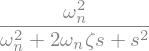

In [27]:
G = omega_n**2/(s**2+2*zeta*omega_n*s + omega_n**2)
G

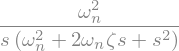

In [28]:
Y_step = 1/s*G
Y_step

In [29]:
a = zeta*omega_n

In [30]:
Ypfe = C1/s + (C2*omega_d + C3*(s+a))/(s**2+2*zeta*omega_n*s + omega_n**2)

In [31]:
import sympy_345

In [32]:
mysolver = sympy_345.partial_fraction_solver(Y_step, Ypfe, [C1,C2,C3])

In [33]:
sol = mysolver.main()

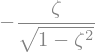

In [34]:
C2a = sol[C2].subs({omega_d:omega_n*sympy.sqrt(1-zeta**2)})
C2a

In [43]:
wd_dict = {omega_d:omega_n*sympy.sqrt(1-zeta**2)}

In [35]:
C1a = sol[C1]
C1a

In [36]:
C3a = sol[C3]
C3a

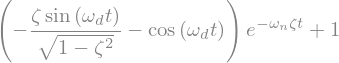

In [38]:
y_step = C1a + sympy.exp(-a*t)*(C2a*sympy.sin(omega_d*t) + C3a*sympy.cos(omega_d*t))
y_step

In [62]:
sympy.print_latex(y_step)

\left(- \frac{\zeta \sin{\left(\omega_{d} t \right)}}{\sqrt{1 - \zeta^{2}}} - \cos{\left(\omega_{d} t \right)}\right) e^{- \omega_{n} \zeta t} + 1


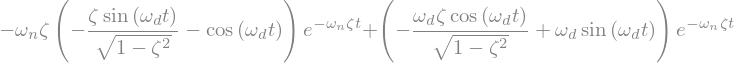

In [39]:
v_step = y_step.diff(t)
v_step

### Note

In the term below, the $\cos$ terms will cancel if we substitute for $\omega_d = \omega_n \sqrt{1-\zeta^2}$

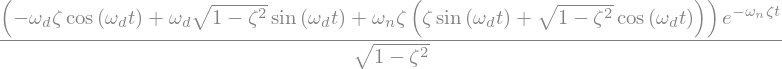

In [53]:
v_step_b = v_step.simplify()
v_step_b

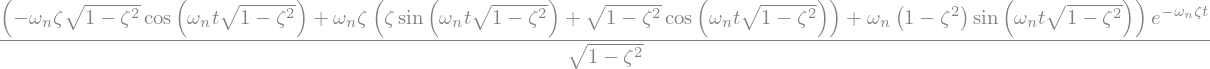

In [54]:
v_step_c = v_step_b.subs(wd_dict)
v_step_c

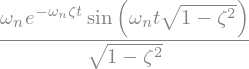

In [55]:
v_step_d = v_step_c.simplify()
v_step_d

In [61]:
sympy.print_latex(v_step_d)

\frac{\omega_{n} e^{- \omega_{n} \zeta t} \sin{\left(\omega_{n} t \sqrt{1 - \zeta^{2}} \right)}}{\sqrt{1 - \zeta^{2}}}


In [59]:
v_step_e = v_step_d.subs({omega_n:omega_d/sympy.sqrt(1-zeta**2)})

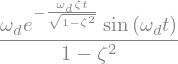

In [60]:
v_step_e

In [41]:
tp_sol = sympy.solve(v_step, t)

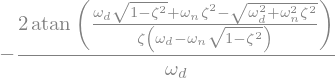

In [46]:
tp_sol[0]

## Find the Peak Response

In [56]:
y_peak = y_step.subs({t:sympy.pi/omega_d})
y_peak

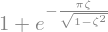

In [57]:
y_peak.subs(wd_dict)

In [58]:
overshoot = y_peak -1
overshoot